<a href="https://colab.research.google.com/github/nickkhymenko/asteria-credit-risk-ml/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Asteria Finance — Exploratory Data Analysis (EDA)

**Module:** IB99Z0 — Programming & Big Data Analytics  
**University:** University of Warwick  
**Project:** Repayment Difficulty Prediction

## 1. Introduction

This notebook presents the initial exploratory data analysis of the loan application dataset provided for the Asteria Finance group assignment.

The objective is to understand the dataset, assess data quality, investigate relationships between applicant characteristics and repayment difficulty, and identify potentially useful features for subsequent machine learning models.

**Target variable:**
- `TARGET = 0`: No repayment difficulty
- `TARGET = 1`: Repayment difficulty

The analysis covers 27,000 loan applications and 122 original variables.

The main areas of investigation include class imbalance, missing values, applicant income, age, financial ratios, and external credit scores.

In [31]:

import pandas as pd

df = pd.read_csv("loan_applications.csv")

df.head()


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0
1,100048,0,Cash loans,F,N,Y,0,202500.0,604152.0,29196.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,5.0
2,100054,0,Cash loans,F,N,Y,0,99000.0,260640.0,26838.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
3,100076,0,Cash loans,M,Y,N,0,180000.0,315000.0,9679.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,100080,0,Revolving loans,F,N,N,1,157500.0,450000.0,22500.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,5.0


In [32]:

print("Number of applications:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of applications: 27000
Number of columns: 122


In [33]:

print(df["TARGET"].value_counts())

print("\nPercentage:")
print(df["TARGET"].value_counts(normalize=True) * 100)


TARGET
0    24820
1     2180
Name: count, dtype: int64

Percentage:
TARGET
0    91.925926
1     8.074074
Name: proportion, dtype: float64


In [34]:

missing = df.isnull().mean() * 100

missing = missing.sort_values(ascending=False)

missing.head(15)


,0
COMMONAREA_AVG,69.640741
COMMONAREA_MODE,69.640741
COMMONAREA_MEDI,69.640741
NONLIVINGAPARTMENTS_MEDI,69.207407
NONLIVINGAPARTMENTS_MODE,69.207407
NONLIVINGAPARTMENTS_AVG,69.207407
LIVINGAPARTMENTS_AVG,68.096296
LIVINGAPARTMENTS_MODE,68.096296
LIVINGAPARTMENTS_MEDI,68.096296
FONDKAPREMONT_MODE,68.088889


In [35]:

df[["AMT_INCOME_TOTAL", "AMT_CREDIT"]].describe()


,AMT_INCOME_TOTAL,AMT_CREDIT
count,2.700000e+04,2.700000e+04
mean,1.686120e+05,6.001821e+05
std,1.061242e+05,4.040661e+05
min,2.700000e+04,4.500000e+04
25%,1.125000e+05,2.700000e+05
50%,1.485000e+05,5.135310e+05
75%,2.025000e+05,8.086500e+05
max,6.750000e+06,3.375000e+06


In [36]:

df.groupby("TARGET")[["AMT_INCOME_TOTAL", "AMT_CREDIT"]].median()


,AMT_INCOME_TOTAL,AMT_CREDIT
TARGET,,
0,148500.0,518562.0
1,135000.0,497520.0


In [37]:

import numpy as np

df["CREDIT_INCOME_RATIO"] = (
    df["AMT_CREDIT"] /
    df["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

df.groupby("TARGET")["CREDIT_INCOME_RATIO"].median()


,CREDIT_INCOME_RATIO
TARGET,
0,3.260870
1,3.257006


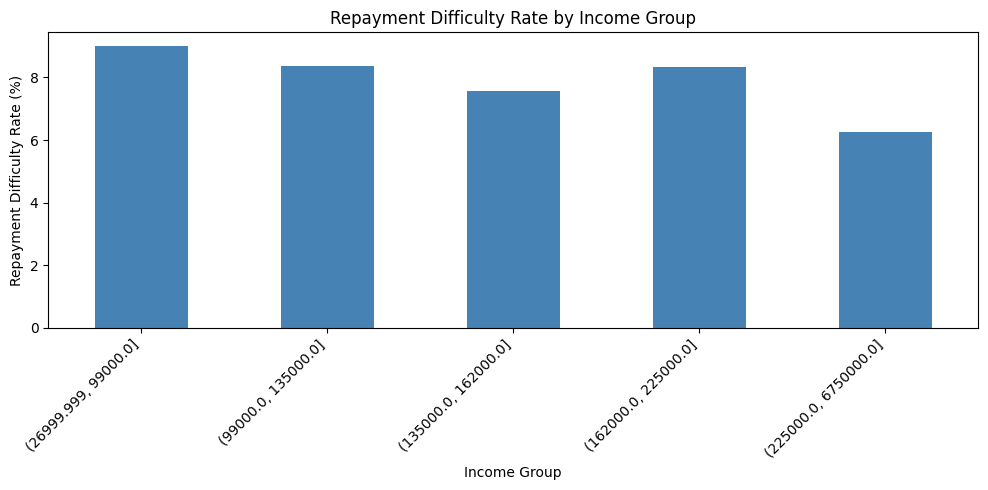

In [38]:

import matplotlib.pyplot as plt

df["INCOME_GROUP"] = pd.qcut(
    df["AMT_INCOME_TOTAL"],
    q=5,
    duplicates="drop"
)

risk_by_income = (
    df.groupby("INCOME_GROUP", observed=True)["TARGET"]
    .mean() * 100
)

risk_by_income.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Repayment Difficulty Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Repayment Difficulty Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### EDA Finding 1 — Income and Repayment Difficulty

Applicants experiencing repayment difficulty have a lower median income (135,000) compared with applicants without repayment difficulty (148,500).

However, the median credit-to-income ratios are almost identical between the two groups (3.257 vs 3.261).

These findings suggest that income may be associated with repayment difficulty, although credit-to-income ratio alone appears to provide limited separation between the two groups.

Further analysis and model validation are required to assess their predictive value.


In [39]:

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25

df.groupby("TARGET")["AGE_YEARS"].median()


,AGE_YEARS
TARGET,
0,43.471595
1,39.273101


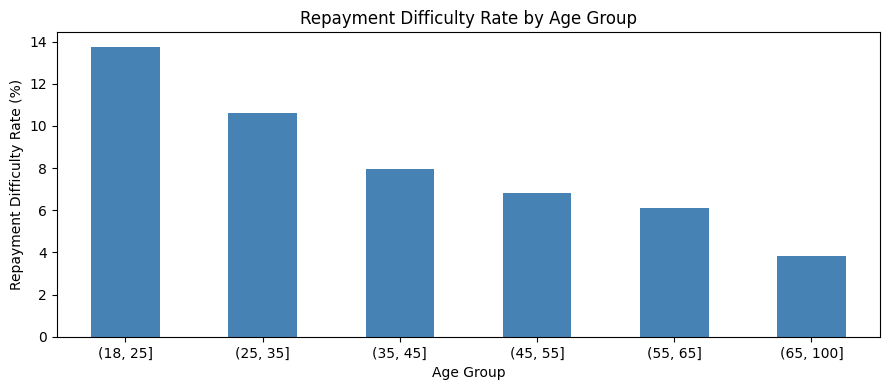

,mean,count
AGE_GROUP,,
"(18, 25]",0.137571,1054
"(25, 35]",0.106199,6356
"(35, 45]",0.079662,7331
"(45, 55]",0.068115,6166
"(55, 65]",0.060964,5413
"(65, 100]",0.038235,680


In [40]:

import matplotlib.pyplot as plt

df["AGE_GROUP"] = pd.cut(
    df["AGE_YEARS"],
    bins=[18, 25, 35, 45, 55, 65, 100]
)

age_risk = (
    df.groupby("AGE_GROUP", observed=True)["TARGET"]
    .agg(["mean", "count"])
)

age_risk["mean"].mul(100).plot(
    kind="bar",
    figsize=(9, 4),
    color="steelblue"
)

plt.title("Repayment Difficulty Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Repayment Difficulty Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(age_risk)


### EDA Finding 2 — Age and Repayment Difficulty

Repayment difficulty rates decrease consistently across age groups, from 13.76% among applicants aged 18–25 to 3.82% among applicants over 65.

The median age of applicants experiencing repayment difficulty is approximately 39.27 years, compared with 43.47 years for applicants without repayment difficulty.

These findings indicate a negative association between applicant age and repayment difficulty.

However, this relationship does not establish causality. Further modelling is required to evaluate its predictive contribution, and the use of age in lending decisions requires careful consideration of fairness and regulatory constraints.

In [41]:

import numpy as np

df["PAYMENT_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] /
    df["AMT_INCOME_TOTAL"].replace(0, np.nan)
)

df.groupby("TARGET")["PAYMENT_INCOME_RATIO"].median()


,PAYMENT_INCOME_RATIO
TARGET,
0,0.162575
1,0.167975


In [42]:

print("Duplicate SK_ID_CURR:",
      df["SK_ID_CURR"].duplicated().sum())

print("Missing TARGET:",
      df["TARGET"].isna().sum())

print("Columns with missing values:",
      (df.isna().sum() > 0).sum())

print("Columns with over 50% missing:",
      (df.isna().mean() > 0.5).sum())

print("\nData types:")
print(df.dtypes.value_counts())


Duplicate SK_ID_CURR: 0
Missing TARGET: 0
Columns with missing values: 67
Columns with over 50% missing: 37

Data types:
float64     68
int64       41
object      16
category     1
category     1
Name: count, dtype: int64


In [43]:

credit_features = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

df[credit_features].describe()


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
count,11732.000000,26943.000000,21605.000000
mean,0.501087,0.513675,0.512512
std,0.210829,0.192331,0.194693
min,0.022339,0.000010,0.000527
25%,0.333105,0.390098,0.372334
50%,0.507710,0.565601,0.537070
75%,0.671646,0.664556,0.670652
max,0.942333,0.855000,0.882530


In [44]:

df.groupby("TARGET")[credit_features].median()


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
TARGET,,,
0,0.519363,0.572950,0.547810
1,0.344490,0.440947,0.377404


### EDA Finding 3 — External Credit Scores

All three external score variables exhibit lower median values among applicants experiencing repayment difficulty.

| Feature | TARGET = 0 | TARGET = 1 |
|---|---:|---:|
| EXT_SOURCE_1 | 0.519 | 0.344 |
| EXT_SOURCE_2 | 0.573 | 0.441 |
| EXT_SOURCE_3 | 0.548 | 0.377 |

Missing values vary considerably across these variables: approximately 56.5% for EXT_SOURCE_1, 20.0% for EXT_SOURCE_3, and 0.2% for EXT_SOURCE_2.

These findings suggest that external scores may be valuable predictors of repayment difficulty.

Missing values will need to be handled within the training pipeline to avoid data leakage, and the predictive contribution of these features will be evaluated during model validation.

## EDA Summary — Asteria Finance

The exploratory analysis covers 27,000 loan applications and 122 original variables. Approximately 8.07% of applicants are labelled as experiencing repayment difficulty, indicating substantial class imbalance.

The dataset contains no duplicate applicant identifiers or missing target values. However, missing data remains an important challenge, with 37 original variables containing more than 50% missing observations.

**Key findings:**

- Applicants experiencing repayment difficulty have lower median incomes (135,000 vs 148,500).
- Younger applicants exhibit higher observed repayment difficulty rates.
- All three external score variables have lower median values among applicants experiencing repayment difficulty.
- Median credit-to-income ratios are similar across the two target groups.

Three numerical features were engineered: applicant age in years, credit-to-income ratio, and payment-to-income ratio.

**Next steps:** investigate the relational datasets, assess historical credit information, develop applicant-level features, and select suitable classification algorithms based on the characteristics of the data.
